In [1]:
%matplotlib inline
import os
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
import json
import warnings
warnings.filterwarnings("ignore", module="tqdm")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display
from sklearn.metrics import f1_score

import hw8

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

OUT = hw8.OUT
FIG = hw8.FIG
LABELS = hw8.TARGET_COLUMNS
print("PyTorch", torch.__version__)
print("Device", hw8.device(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print("Seed", hw8.SEED, "| threshold", hw8.THRESHOLD)
print("Artifacts", OUT)


PyTorch 2.14.0+cu130
Device cuda NVIDIA L40S-48C
Seed 281026 | threshold 0.5
Artifacts /home/vnikolaieva/ML/week8/outputs/hw8


## Data and split

Train 19,708 | validation 4,719 | HPA 1,717


,train_rate,train_count,val_count,hpa_count
Cytoplasm,0.408,8039,1831,562
Nucleus,0.391,7703,2017,893
Cell membrane,0.177,3490,697,287
Mitochondrion,0.105,2074,516,196
Endoplasmic reticulum,0.091,1784,396,77
Lysosome/Vacuole,0.064,1253,243,2
Golgi apparatus,0.055,1087,192,86
Peroxisome,0.013,251,53,7


Labels per training protein: {1: 14496, 2: 4582, 3: 515, 4: 99, 5: 16}


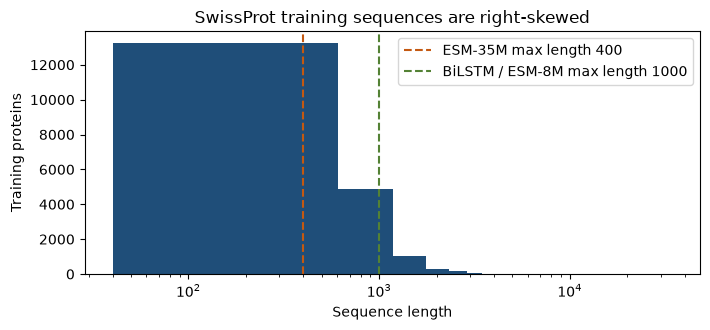

Median length 462. Fraction longer than 400: 58.1%. Fraction longer than 1000: 12.3%.
Truncation keeps the N-terminus. C-terminal signals, including the peroxisomal PTS1 motif, are dropped for proteins longer than the cutoff.


In [2]:
train, val, test = hw8.load_frames()
print(f"Train {len(train):,} | validation {len(val):,} | HPA {len(test):,}")

prevalence = pd.DataFrame({
    "train_rate": train[LABELS].mean(),
    "train_count": train[LABELS].sum().astype(int),
    "val_count": val[LABELS].sum().astype(int),
    "hpa_count": test[LABELS].sum().astype(int),
})
display(prevalence)

labels_per_protein = train[LABELS].sum(axis=1).astype(int)
print("Labels per training protein:", labels_per_protein.value_counts().sort_index().to_dict())

lengths = train["sequence"].str.len()
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.hist(lengths, bins=60, color="#1f4e79")
ax.set_xscale("log")
ax.axvline(400, color="#c45911", ls="--", label="ESM-35M max length 400")
ax.axvline(1000, color="#548235", ls="--", label="BiLSTM / ESM-8M max length 1000")
ax.set_xlabel("Sequence length")
ax.set_ylabel("Training proteins")
ax.set_title("SwissProt training sequences are right-skewed")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Median length {lengths.median():.0f}. Fraction longer than 400: {(lengths > 400).mean():.1%}. Fraction longer than 1000: {(lengths > 1000).mean():.1%}.")
print("Truncation keeps the N-terminus. C-terminal signals, including the peroxisomal PTS1 motif, are dropped for proteins longer than the cutoff.")


## Part A; Baselines

**BiLSTM, trained from scratch.** Vocabulary is the 20 standard amino acids plus `<PAD>` (to fill empty positions in shorter sequences) and `<UNK>` (non-standard, ambiguous, or rare amino acids) (`B`, `U`, and `X` in SwissProt map to `<UNK>`). Each residue is a 64-dimensional embedding, as in practical. A bidirectional LSTM with hidden size 128 (from practical) reads the sequence, and a linear layer maps the concatenated final states to eight logits. Sequences are packed, so the state is the last real residue rather than a padding step. The practical notebook's LSTM consumes the padded tail and lets pad tokens overwrite that state. Maximum length 1000, batch size 64, Adam at `1e-3`, 8 epochs. The loss is `BCEWithLogitsLoss` with `pos_weight = n_negative / n_positive` computed on the training split. The checkpoint with the best validation macro-F1 is the one scored on HPA.

**ESM-2 8M frozen embeddings + logistic probe.** Protein vectors are the masked mean of the last hidden state from `facebook/esm2_t6_8M_UR50D`, truncated at 1000 residues. They are the practical's cached table `esm2_embeddings.parquet` (320 dimensions; 19,708 / 4,719 / 1,717 rows). A one-protein recomputation matches the cache. The downstream model is one-vs-rest logistic regression, `class_weight='balanced'`, `max_iter=2000`, `random_state=281026`, refit in this homework.


In [3]:
summary_path = OUT / "summary.json"
if not summary_path.exists():
    hw8.run_all()
summary = json.loads(summary_path.read_text())

# Provenance check: one cached vector against a fresh ESM-2 8M forward pass.
from transformers import AutoModel, AutoTokenizer

spot_id = train.iloc[0]["protein_id"]
cached = pd.read_parquet(hw8.WEEK_DIR / "esm2_embeddings.parquet")
cached_row = cached.loc[cached["protein_id"] == spot_id].iloc[0]
feature_cols = [column for column in cached.columns if column.startswith("esm_")]
tokenizer = AutoTokenizer.from_pretrained(hw8.ESM8_NAME)
encoder = AutoModel.from_pretrained(hw8.ESM8_NAME).eval()
encoded = tokenizer(train.iloc[0]["sequence"], return_tensors="pt", truncation=True, max_length=hw8.ESM8_MAX_LEN)
with torch.no_grad():
    hidden = encoder(**encoded).last_hidden_state
mask = encoded["attention_mask"].unsqueeze(-1).float()
fresh = ((hidden * mask).sum(1) / mask.sum(1)).numpy().ravel()
stored = cached_row[feature_cols].to_numpy(dtype=np.float32)
cosine = float(np.dot(fresh, stored) / (np.linalg.norm(fresh) * np.linalg.norm(stored)))
print(f"Embedding spot check {spot_id}: cosine {cosine:.6f}, max abs diff {np.max(np.abs(fresh - stored)):.2e}")

bilstm = summary["bilstm"]
probe = summary["probe"]


def headline(name, block_val, block_test):
    return {
        "model": name,
        "val_macro_f1": block_val["macro_f1"],
        "val_micro_f1": block_val["micro_f1"],
        "val_exact_match": block_val["exact_match"],
        "hpa_macro_f1": block_test["macro_f1"],
        "hpa_micro_f1": block_test["micro_f1"],
        "hpa_exact_match": block_test["exact_match"],
    }

part_a = pd.DataFrame([
    headline("BiLSTM", bilstm["validation"], bilstm["hpa_test"]),
    headline("ESM-2 8M + logistic", probe["full_validation"], probe["full_hpa_test"]),
])
display(part_a)

settings = pd.DataFrame([
    {
        "model": "BiLSTM",
        "seed": bilstm["config"]["seed"],
        "max_length": bilstm["config"]["max_length"],
        "batch_size": bilstm["config"]["batch_size"],
        "epochs": bilstm["config"]["epochs"],
        "best_epoch": bilstm["config"]["best_epoch"],
        "learning_rate": bilstm["config"]["learning_rate"],
        "threshold": bilstm["config"]["threshold"],
        "trainable_parameters": bilstm["config"]["trainable_parameters"],
        "seconds_per_epoch": bilstm["config"]["mean_seconds_per_epoch"],
        "peak_gpu_mib": bilstm["config"]["peak_gpu_memory_mib"],
    },
    {
        "model": "ESM-2 8M + logistic",
        "seed": probe["config"]["seed"],
        "max_length": probe["config"]["embedding_max_length"],
        "batch_size": "n/a (cached vectors)",
        "epochs": "1 fit",
        "best_epoch": "n/a",
        "learning_rate": "lbfgs default",
        "threshold": probe["config"]["threshold"],
        "trainable_parameters": probe["config"]["trainable_parameters"],
        "seconds_per_epoch": next(row["fit_seconds"] for row in probe["fractions"] if row["fraction"] == 1.0),
        "peak_gpu_mib": 0.0,
    },
])
display(settings)



Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 6419.08it/s]

Embedding spot check Q0GA42: cosine 1.000000, max abs diff 9.54e-07


,model,val_macro_f1,val_micro_f1,val_exact_match,hpa_macro_f1,hpa_micro_f1,hpa_exact_match
0,BiLSTM,0.401,0.524,0.120,0.266,0.407,0.065
1,ESM-2 8M + logistic,0.439,0.549,0.216,0.299,0.467,0.138


,model,seed,max_length,batch_size,epochs,best_epoch,learning_rate,threshold,trainable_parameters,seconds_per_epoch,peak_gpu_mib
0,BiLSTM,281026,1000,64,8,6,0.001,0.500,202120,17.150,583.300
1,ESM-2 8M + logistic,281026,1000,n/a (cached vectors),1 fit,n/a,lbfgs default,0.500,2568,19.481,0.000


BiLSTM per-compartment scores


,split,compartment,support,precision,recall,f1
0,validation,Cytoplasm,1831,0.518,0.874,0.650
1,validation,Nucleus,2017,0.593,0.886,0.711
2,validation,Cell membrane,697,0.359,0.735,0.482
3,validation,Mitochondrion,516,0.434,0.641,0.518
4,validation,Endoplasmic reticulum,396,0.268,0.826,0.404
5,validation,Lysosome/Vacuole,243,0.089,0.486,0.150
6,validation,Golgi apparatus,192,0.088,0.521,0.150
7,validation,Peroxisome,53,0.081,0.679,0.144
8,HPA,Cytoplasm,562,0.368,0.696,0.482
9,HPA,Nucleus,893,0.621,0.744,0.677


ESM-2 8M logistic probe, full training set


,split,compartment,support,precision,recall,f1
0,validation,Cytoplasm,1831,0.588,0.783,0.672
1,validation,Nucleus,2017,0.706,0.803,0.751
2,validation,Cell membrane,697,0.529,0.762,0.625
3,validation,Mitochondrion,516,0.418,0.845,0.560
4,validation,Endoplasmic reticulum,396,0.293,0.795,0.428
5,validation,Lysosome/Vacuole,243,0.120,0.621,0.201
6,validation,Golgi apparatus,192,0.097,0.604,0.167
7,validation,Peroxisome,53,0.058,0.717,0.108
8,HPA,Cytoplasm,562,0.398,0.746,0.519
9,HPA,Nucleus,893,0.651,0.764,0.703


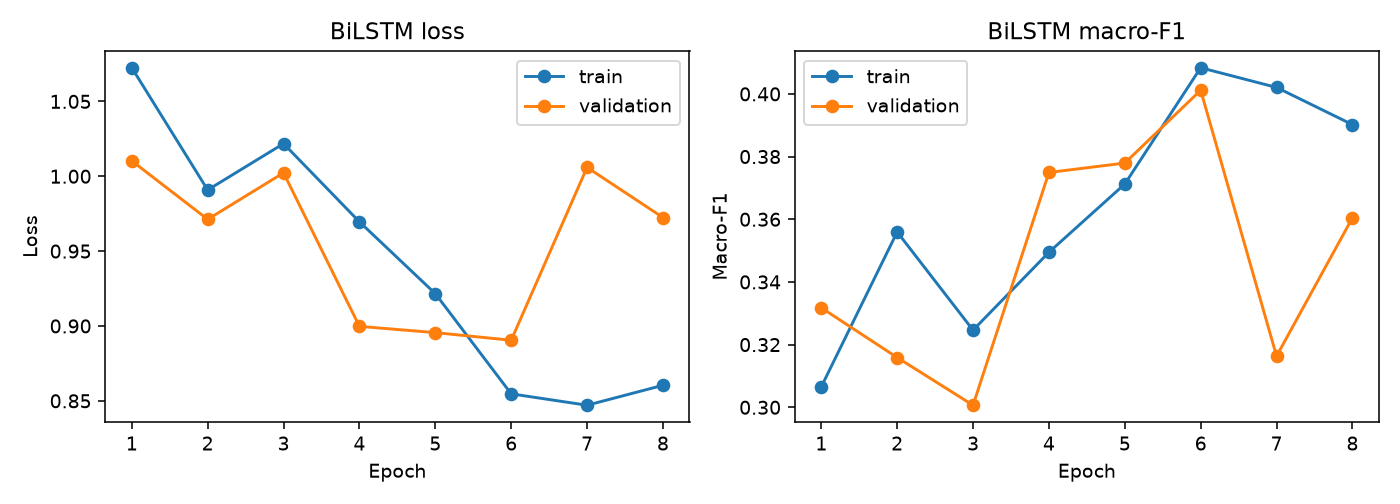

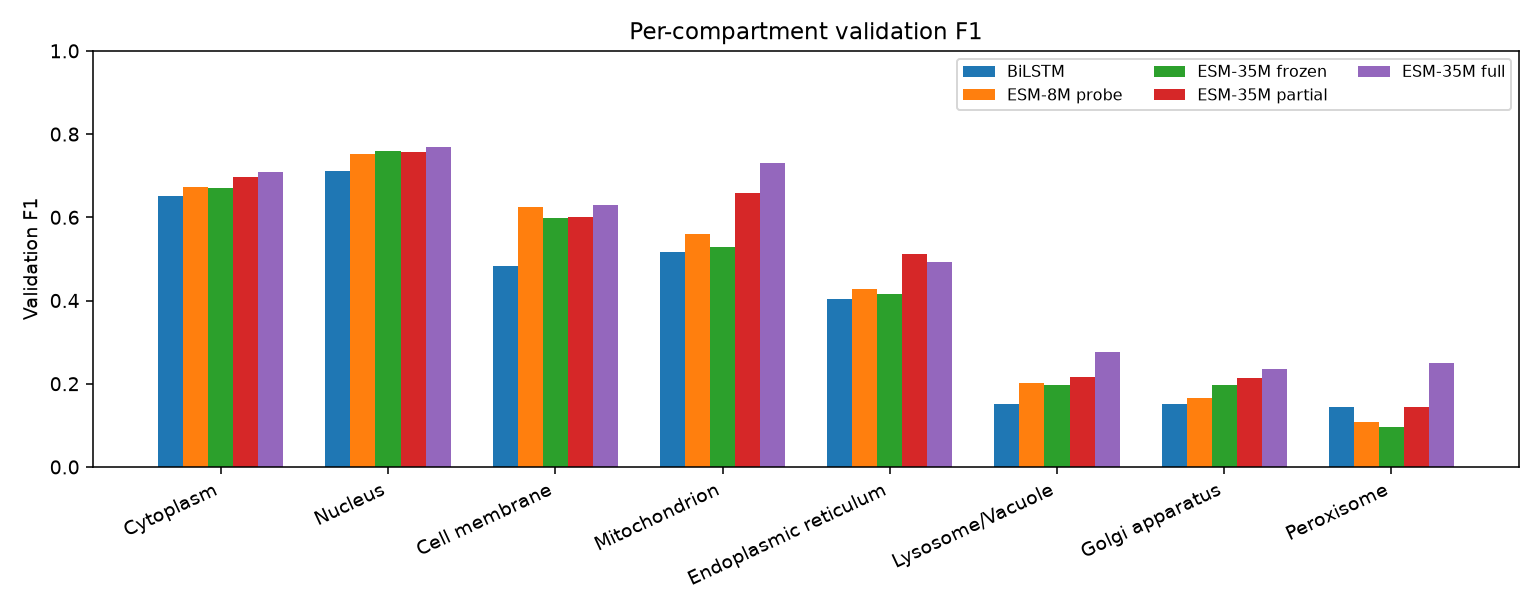

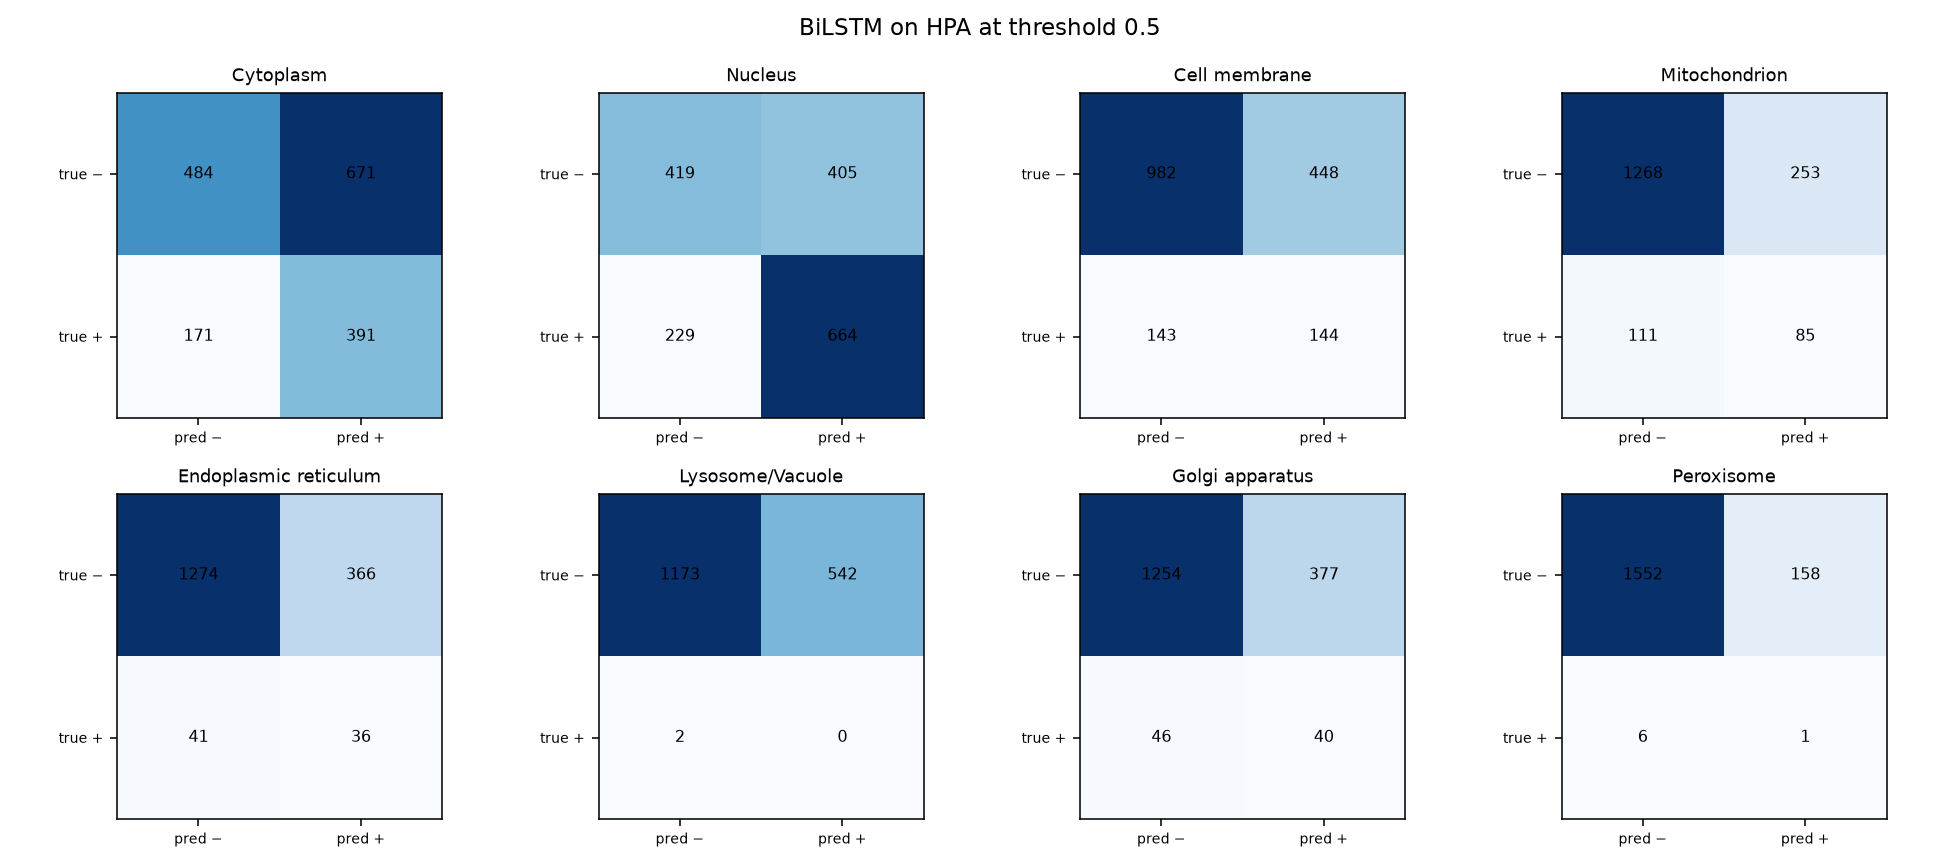

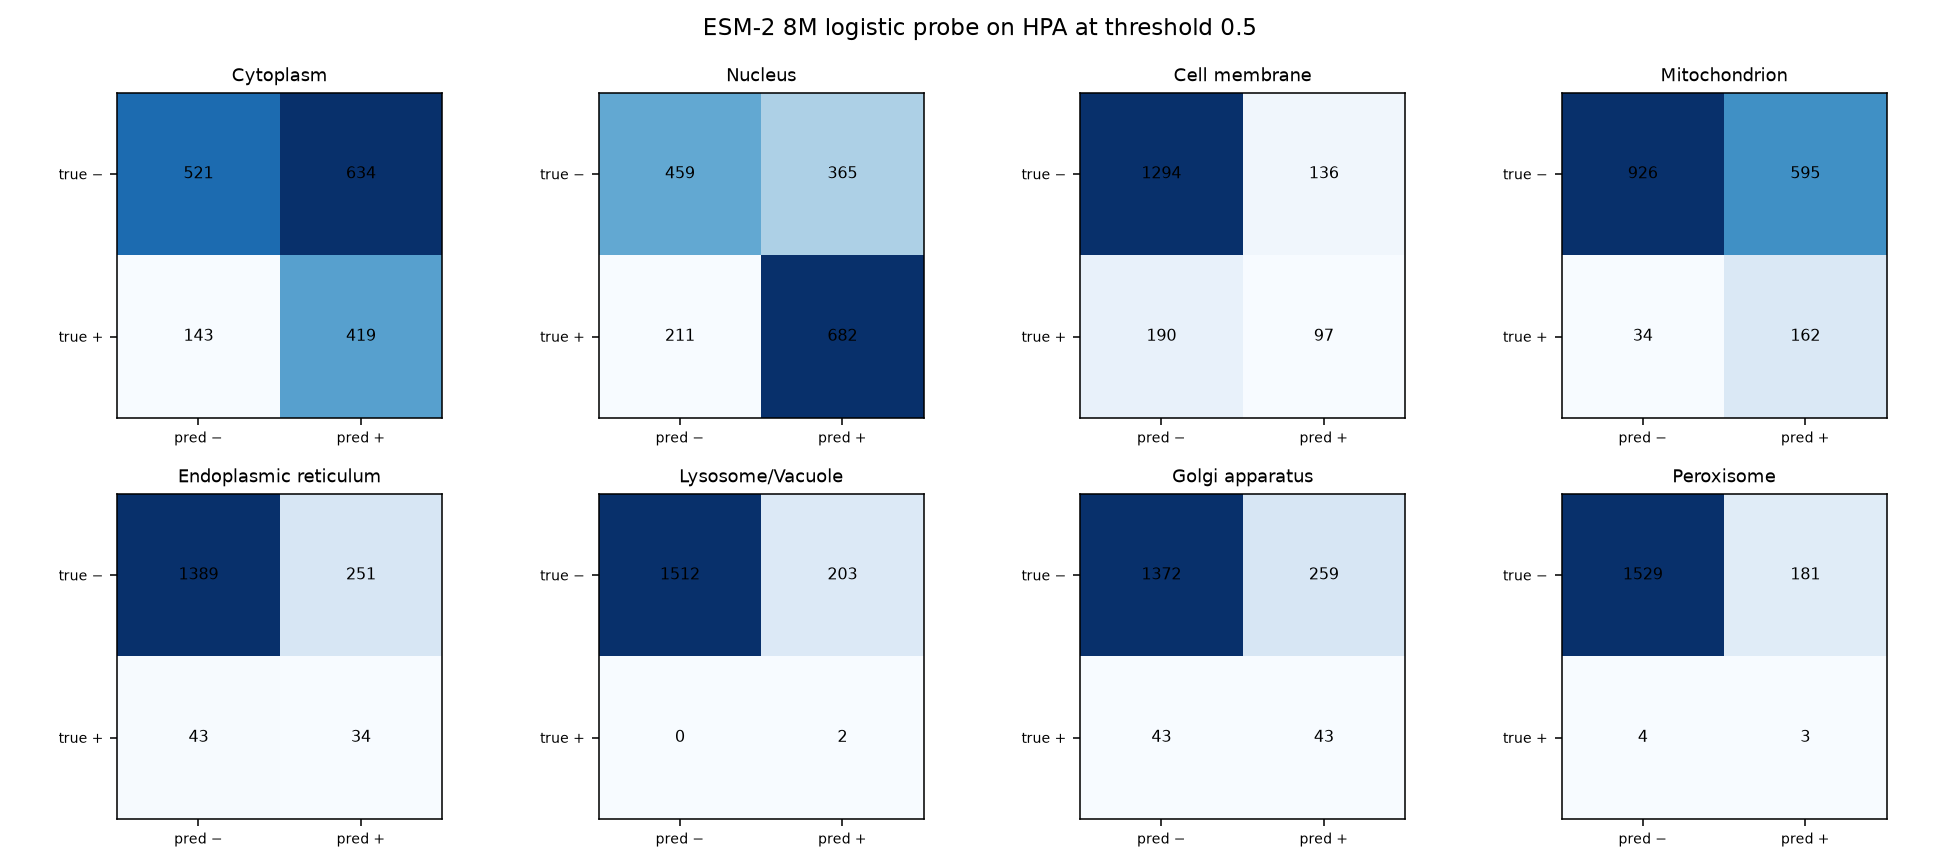

In [4]:
def class_table(block, split):
    rows = []
    for label in LABELS:
        stats = block["per_class"][label]
        rows.append({
            "split": split,
            "compartment": label,
            "support": stats["support"],
            "precision": stats["precision"],
            "recall": stats["recall"],
            "f1": stats["f1"],
        })
    return pd.DataFrame(rows)

print("BiLSTM per-compartment scores")
display(pd.concat([
    class_table(bilstm["validation"], "validation"),
    class_table(bilstm["hpa_test"], "HPA"),
], ignore_index=True))
print("ESM-2 8M logistic probe, full training set")
display(pd.concat([
    class_table(probe["full_validation"], "validation"),
    class_table(probe["full_hpa_test"], "HPA"),
], ignore_index=True))

display(Image(filename=str(FIG / "bilstm_curves.png")))
display(Image(filename=str(FIG / "per_class_val_f1.png")))

bilstm_pred = np.load(OUT / "bilstm" / "predictions.npz")
probe_pred = np.load(OUT / "esm8m_probe" / "predictions.npz")
hw8.confusion_figure(
    bilstm_pred["y_test"], bilstm_pred["p_test"],
    "BiLSTM on HPA at threshold 0.5", FIG / "bilstm_hpa_confusion.png",
)
hw8.confusion_figure(
    probe_pred["y_test"], probe_pred["p_test_full"],
    "ESM-2 8M logistic probe on HPA at threshold 0.5", FIG / "probe_hpa_confusion.png",
)
display(Image(filename=str(FIG / "bilstm_hpa_confusion.png")))
display(Image(filename=str(FIG / "probe_hpa_confusion.png")))


In [5]:
def error_rates(y_true, y_prob, threshold=0.5):
    pred = (y_prob >= threshold).astype(int)
    return {
        "false_positive_labels": int(((pred == 1) & (y_true == 0)).sum()),
        "false_negative_labels": int(((pred == 0) & (y_true == 1)).sum()),
        "proteins_with_a_false_positive": float(((pred == 1) & (y_true == 0)).any(axis=1).mean()),
        "proteins_with_a_missed_label": float(((pred == 0) & (y_true == 1)).any(axis=1).mean()),
    }

error_view = pd.DataFrame([
    {"model": "BiLSTM", "split": "validation", **error_rates(bilstm_pred["y_val"], bilstm_pred["p_val"])},
    {"model": "BiLSTM", "split": "HPA", **error_rates(bilstm_pred["y_test"], bilstm_pred["p_test"])},
    {"model": "ESM-2 8M + logistic", "split": "validation", **error_rates(probe_pred["y_val"], probe_pred["p_val_full"])},
    {"model": "ESM-2 8M + logistic", "split": "HPA", **error_rates(probe_pred["y_test"], probe_pred["p_test_full"])},
])
display(error_view)

# Validation-only sensitivity check. Not used for the reported HPA numbers.
grid = np.linspace(0.05, 0.95, 19)
chosen = []
for column in range(bilstm_pred["y_val"].shape[1]):
    scores = [
        f1_score(bilstm_pred["y_val"][:, column], bilstm_pred["p_val"][:, column] >= threshold, zero_division=0)
        for threshold in grid
    ]
    chosen.append(float(grid[int(np.argmax(scores))]))
tuned = np.column_stack([
    (bilstm_pred["p_val"][:, column] >= chosen[column]).astype(int) for column in range(len(LABELS))
])
tuned_macro = f1_score(bilstm_pred["y_val"], tuned, average="macro", zero_division=0)
print(
    "BiLSTM validation macro-F1 at 0.5:",
    f"{f1_score(bilstm_pred['y_val'], bilstm_pred['p_val'] >= 0.5, average='macro', zero_division=0):.3f}",
)
print("Per-class validation thresholds:", dict(zip(LABELS, [round(value, 2) for value in chosen])))
print(f"Validation macro-F1 at those thresholds: {tuned_macro:.3f}. HPA was not retuned.")


,model,split,false_positive_labels,false_negative_labels,proteins_with_a_false_positive,proteins_with_a_missed_label
0,BiLSTM,validation,7621,1132,0.864,0.214
1,BiLSTM,HPA,3220,749,0.921,0.393
2,ESM-2 8M + logistic,validation,6323,1305,0.734,0.252
3,ESM-2 8M + logistic,HPA,2624,668,0.836,0.352


BiLSTM validation macro-F1 at 0.5: 0.401
Per-class validation thresholds: {'Cytoplasm': 0.55, 'Nucleus': 0.45, 'Cell membrane': 0.7, 'Mitochondrion': 0.65, 'Endoplasmic reticulum': 0.75, 'Lysosome/Vacuole': 0.7, 'Golgi apparatus': 0.65, 'Peroxisome': 0.95}
Validation macro-F1 at those thresholds: 0.446. HPA was not retuned.


## Part B: Data efficiency

The downstream model is the same ESM-2 8M logistic probe. Validation, HPA, preprocessing, and the seed stay fixed. One permutation of the training rows is drawn with seed 281026. The 10% subset is a prefix of the 50% subset, which is a prefix of the full set, so the curve is nested rather than three independent samples.

**Selection rule, validation only:** keep the smallest subset whose validation macro-F1 is within 0.01 of the best subset. HPA is scored for that selected subset, and also for the full probe because Part A requires the full-data baseline. The 10% model is not scored on HPA.


,fraction,n_train,peroxisome_positives,val_macro_f1,val_micro_f1,val_exact_match,fit_seconds
0,10%,1971,21,0.425,0.546,0.207,9.304
1,50%,9854,109,0.432,0.547,0.214,16.057
2,100%,19708,251,0.439,0.549,0.216,19.481


Selected fraction 50% with validation macro-F1 0.432 and HPA macro-F1 0.296.


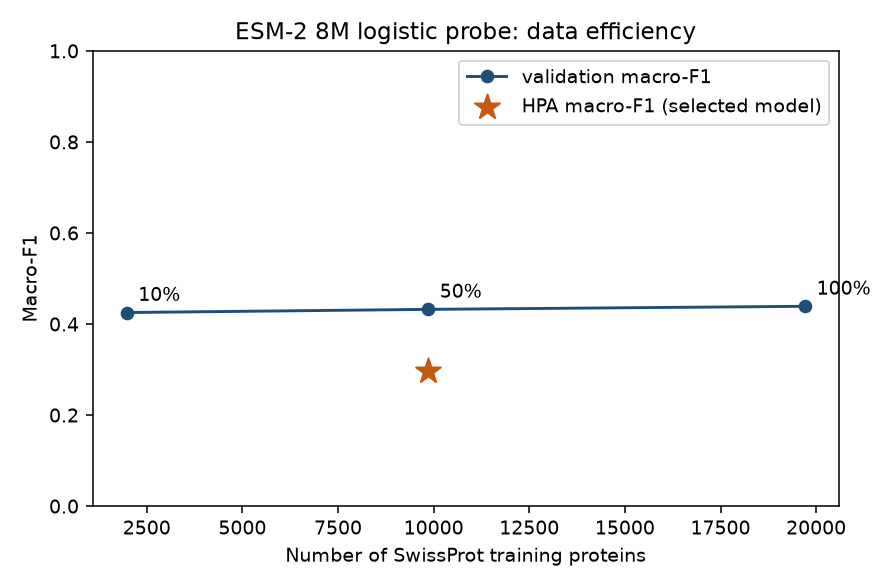

In [6]:
fraction_rows = []
for row in probe["fractions"]:
    fraction_rows.append({
        "fraction": f"{row['fraction']:.0%}",
        "n_train": row["n_train"],
        "peroxisome_positives": row["positive_counts"]["Peroxisome"],
        "val_macro_f1": row["val_macro_f1"],
        "val_micro_f1": row["val_micro_f1"],
        "val_exact_match": row["val_exact_match"],
        "fit_seconds": row["fit_seconds"],
    })
display(pd.DataFrame(fraction_rows))
print(
    f"Selected fraction {probe['selected_fraction']:.0%} "
    f"with validation macro-F1 {probe['selected_validation']['macro_f1']:.3f} "
    f"and HPA macro-F1 {probe['selected_hpa_test']['macro_f1']:.3f}."
)
display(Image(filename=str(FIG / "data_efficiency.png")))


## Part C — Frozen versus fine-tuned ESM-2 35M

`facebook/esm2_t12_35M_UR50D`, same splits and the same `pos_weight` BCE loss as `train_esm.py`. A linear head sits on the masked mean of the last hidden state. Maximum length 400 and batch size 32 (the course script's default length; batch 32 fits the local L40S and is larger than the script's default of 8). Seed 281026. Threshold 0.5. Five epochs. Learning rate `1e-3` for the frozen head and `2e-5` for partial and full updates, which is the script's rule. The best validation-macro-F1 epoch is reloaded before the single HPA pass.

| Mode | What is trainable |
|---|---|
| frozen | classification head only (3,848 parameters); backbone in eval mode |
| partial | head + last 2 of 12 transformer blocks |
| full | every backbone parameter and the head |

These runs used the local NVIDIA L40S (48 GB) and the course training procedure. They were not launched through `vcc-server-kse`. ESM-2 150M was left out; the required comparison is the three 35M modes. Checkpoints were not kept after evaluation, so the disk only holds metrics, histories, and predictions. In the table below, the logistic-probe "time/epoch" is the wall-clock of one fit, not an epoch.


,Model,Training mode,Trainable parameters,Max length,Batch size,Val macro-F1,HPA macro-F1,Time/epoch (s),Peak GPU memory (MiB)
0,BiLSTM,from scratch,"202,120",1000,64,0.401,0.266,17.1,583
1,ESM-2 8M + logistic probe,frozen embeddings,"2,568",1000,—,0.439,0.299,19.5,0
2,ESM-2 35M + head,frozen,"3,848",400,32,0.433,0.304,57.1,619
3,ESM-2 35M,partial,"5,545,928",400,32,0.475,0.322,72.5,1892
4,ESM-2 35M,full,"33,504,249",400,32,0.512,0.349,144.6,8123


,Model,Training mode,Val macro-F1,Val micro-F1,Val exact-match,HPA macro-F1,HPA micro-F1,HPA exact-match,Best epoch
0,BiLSTM,from scratch,0.401,0.524,0.120,0.266,0.407,0.065,6
1,ESM-2 8M + logistic probe,frozen embeddings,0.439,0.549,0.216,0.299,0.467,0.138,—
2,ESM-2 35M + head,frozen,0.433,0.538,0.173,0.304,0.444,0.113,5
3,ESM-2 35M,partial,0.475,0.576,0.242,0.322,0.471,0.167,5
4,ESM-2 35M,full,0.512,0.626,0.337,0.349,0.534,0.239,5


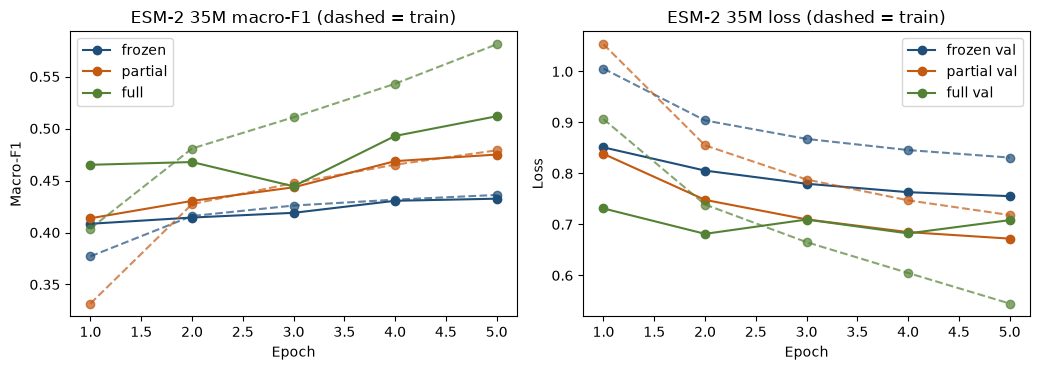

,mode,compartment,val_f1_frozen,val_f1,val_delta,hpa_f1_frozen,hpa_f1,hpa_delta,hpa_support
0,partial,Cytoplasm,0.670,0.696,0.026,0.541,0.535,-0.005,562
1,partial,Nucleus,0.759,0.758,-0.001,0.706,0.697,-0.008,893
2,partial,Cell membrane,0.598,0.602,0.004,0.384,0.437,0.053,287
3,partial,Mitochondrion,0.530,0.659,0.129,0.355,0.379,0.023,196
4,partial,Endoplasmic reticulum,0.415,0.511,0.096,0.160,0.224,0.064,77
5,partial,Lysosome/Vacuole,0.196,0.216,0.020,0.011,0.012,0.001,2
6,partial,Golgi apparatus,0.197,0.213,0.017,0.244,0.251,0.006,86
7,partial,Peroxisome,0.096,0.144,0.048,0.027,0.042,0.014,7
8,full,Cytoplasm,0.670,0.708,0.039,0.541,0.558,0.017,562
9,full,Nucleus,0.759,0.769,0.010,0.706,0.711,0.006,893


In [7]:
comparison = pd.read_csv(OUT / "comparison_table.csv")
homework_table = comparison[[
    "Model", "Training mode", "Trainable parameters", "Max length", "Batch size",
    "Val macro-F1", "HPA macro-F1", "Time/epoch (s)", "Peak GPU memory (MiB)",
]].copy()
def as_int_or_blank(value):
    if pd.isna(value) or value == "":
        return "—"
    return f"{int(float(value)):,}"

homework_table["Trainable parameters"] = homework_table["Trainable parameters"].map(as_int_or_blank)
homework_table["Batch size"] = homework_table["Batch size"].map(as_int_or_blank)
homework_table["Time/epoch (s)"] = homework_table["Time/epoch (s)"].map(lambda value: f"{value:.1f}" if pd.notna(value) else "")
homework_table["Peak GPU memory (MiB)"] = homework_table["Peak GPU memory (MiB)"].map(
    lambda value: f"{value:.0f}" if pd.notna(value) else ""
)
display(homework_table)
extended = comparison[[
    "Model", "Training mode", "Val macro-F1", "Val micro-F1", "Val exact-match",
    "HPA macro-F1", "HPA micro-F1", "HPA exact-match", "Best epoch",
]].copy()
extended["Best epoch"] = extended["Best epoch"].map(as_int_or_blank)
display(extended)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for mode, color in (("frozen", "#1f4e79"), ("partial", "#c45911"), ("full", "#548235")):
    history = pd.DataFrame(summary["esm35"][mode]["history"])
    axes[0].plot(history["epoch"], history["val_macro_f1"], marker="o", color=color, label=mode)
    axes[0].plot(history["epoch"], history["train_macro_f1"], marker="o", color=color, ls="--", alpha=0.7)
    axes[1].plot(history["epoch"], history["val_loss"], marker="o", color=color, label=f"{mode} val")
    axes[1].plot(history["epoch"], history["train_loss"], marker="o", color=color, ls="--", alpha=0.7)
axes[0].set_title("ESM-2 35M macro-F1 (dashed = train)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Macro-F1")
axes[0].legend()
axes[1].set_title("ESM-2 35M loss (dashed = train)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
fig.tight_layout()
plt.show()

delta_rows = []
frozen_val = summary["esm35"]["frozen"]["validation"]["per_class_f1"]
frozen_hpa = summary["esm35"]["frozen"]["hpa_test"]["per_class_f1"]
for mode in ("partial", "full"):
    for label in LABELS:
        delta_rows.append({
            "mode": mode,
            "compartment": label,
            "val_f1_frozen": frozen_val[label],
            "val_f1": summary["esm35"][mode]["validation"]["per_class_f1"][label],
            "val_delta": summary["esm35"][mode]["validation"]["per_class_f1"][label] - frozen_val[label],
            "hpa_f1_frozen": frozen_hpa[label],
            "hpa_f1": summary["esm35"][mode]["hpa_test"]["per_class_f1"][label],
            "hpa_delta": summary["esm35"][mode]["hpa_test"]["per_class_f1"][label] - frozen_hpa[label],
            "hpa_support": summary["esm35"][mode]["hpa_test"]["per_class"][label]["support"],
        })
delta = pd.DataFrame(delta_rows)
display(delta)


In [8]:
def gap(block):
    return block["validation"]["macro_f1"] - block["hpa_test"]["macro_f1"]

def epoch_note(history):
    frame = pd.DataFrame(history)
    best = frame.loc[frame["val_macro_f1"].idxmax()]
    last = frame.iloc[-1]
    train_val_gap = float(best["train_macro_f1"] - best["val_macro_f1"])
    later = frame.loc[frame["epoch"] > best["epoch"]]
    val_loss_rose = bool((later["val_loss"] > best["val_loss"] + 0.02).any()) if len(later) else False
    still_best_at_end = int(best["epoch"]) == int(last["epoch"])
    return {
        "best_epoch": int(best["epoch"]),
        "train_f1_at_best": float(best["train_macro_f1"]),
        "val_f1_at_best": float(best["val_macro_f1"]),
        "train_minus_val": train_val_gap,
        "val_loss_rose_after_best": val_loss_rose,
        "best_is_last_epoch": still_best_at_end,
        "last_val_loss": float(last["val_loss"]),
        "best_val_loss": float(best["val_loss"]),
    }

notes = {mode: epoch_note(summary["esm35"][mode]["history"]) for mode in ("frozen", "partial", "full")}
display(pd.DataFrame(notes).T)

lines = []
for mode in ("frozen", "partial", "full"):
    cfg = summary["esm35"][mode]["config"]
    val = summary["esm35"][mode]["validation"]
    hpa = summary["esm35"][mode]["hpa_test"]
    note = notes[mode]
    lines.append(
        f"**ESM-2 35M {mode}.** Trainable parameters {cfg['trainable_parameters']:,}. "
        f"Best epoch {cfg['best_epoch']} of {cfg['epochs']}. "
        f"Validation macro-F1 {val['macro_f1']:.3f}, micro-F1 {val['micro_f1']:.3f}, exact-match {val['exact_match']:.3f}. "
        f"HPA macro-F1 {hpa['macro_f1']:.3f}, micro-F1 {hpa['micro_f1']:.3f}, exact-match {hpa['exact_match']:.3f}. "
        f"Mean time per epoch {cfg['mean_seconds_per_epoch']:.1f} s. "
        f"Peak allocated GPU memory {cfg['peak_gpu_memory_mib']:.0f} MiB. "
        f"At the chosen epoch, train macro-F1 minus validation macro-F1 is {note['train_minus_val']:+.3f}."
    )
display(Markdown("\n\n".join(lines)))


,best_epoch,train_f1_at_best,val_f1_at_best,train_minus_val,val_loss_rose_after_best,best_is_last_epoch,last_val_loss,best_val_loss
frozen,5,0.436,0.433,0.004,False,True,0.755,0.755
partial,5,0.479,0.475,0.004,False,True,0.672,0.672
full,5,0.581,0.512,0.069,False,True,0.708,0.708


**ESM-2 35M frozen.** Trainable parameters 3,848. Best epoch 5 of 5. Validation macro-F1 0.433, micro-F1 0.538, exact-match 0.173. HPA macro-F1 0.304, micro-F1 0.444, exact-match 0.113. Mean time per epoch 57.1 s. Peak allocated GPU memory 619 MiB. At the chosen epoch, train macro-F1 minus validation macro-F1 is +0.004.

**ESM-2 35M partial.** Trainable parameters 5,545,928. Best epoch 5 of 5. Validation macro-F1 0.475, micro-F1 0.576, exact-match 0.242. HPA macro-F1 0.322, micro-F1 0.471, exact-match 0.167. Mean time per epoch 72.5 s. Peak allocated GPU memory 1892 MiB. At the chosen epoch, train macro-F1 minus validation macro-F1 is +0.004.

**ESM-2 35M full.** Trainable parameters 33,504,249. Best epoch 5 of 5. Validation macro-F1 0.512, micro-F1 0.626, exact-match 0.337. HPA macro-F1 0.349, micro-F1 0.534, exact-match 0.239. Mean time per epoch 144.6 s. Peak allocated GPU memory 8123 MiB. At the chosen epoch, train macro-F1 minus validation macro-F1 is +0.069.